# Modularity on the Karate Club Graph
Recursive spectral modularity partitioning (Newman, 2006) on Zachary's Karate Club network.
The method is explained step by step in the README.

In [1]:
import os
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

os.makedirs("assets", exist_ok=True)

## 1. Load the graph and build the modularity matrix
Build the adjacency matrix `A`, the degrees `k`, and the modularity matrix `B = A - k kᵀ / 2m`.
`B` measures how much more connected two nodes are than expected by chance.
(`weight=None` is needed because NetworkX stores edge weights for this graph, but we want a 0/1 matrix.)

In [2]:
G = nx.karate_club_graph()
n, m = G.number_of_nodes(), G.number_of_edges()

A = nx.to_numpy_array(G, weight=None)
k = A.sum(axis=1)
B = A - np.outer(k, k) / (2 * m)

print("nodes:", n, "| edges:", m)

nodes: 34 | edges: 78


## 2. Split one community
Take the block of `B` for the community, find its leading eigenvector, and split the nodes by its sign.
The leading eigenvector is the best relaxed solution of the modularity maximisation. If the leading eigenvalue is ≤ 0, no split helps, so the community is left as it is.

In [3]:
def split(group):
    Bc = B[np.ix_(group, group)]              # modularity matrix restricted to the group
    values, vectors = np.linalg.eigh(Bc)      # eigenvalues in increasing order
    if values[-1] <= 1e-9:                    # leading eigenvalue <= 0 -> stop
        return None
    u = vectors[:, -1]                        # leading eigenvector
    if u[0] < 0:                              # eigenvector sign is arbitrary; fix it for reproducibility
        u = -u
    plus  = [v for v, x in zip(group, u) if x > 0]
    minus = [v for v, x in zip(group, u) if x <= 0]
    if len(plus) == 0 or len(minus) == 0:     # nothing was actually split
        return None
    return plus, minus

## 3. Repeat on every new community
Start with all nodes in one community and keep splitting until nothing can be split. Each successful split is one iteration, and the partition is saved after each one.
This gives more than two communities, and the partitions needed for the plots and metrics.

In [4]:
def modularity(partition):
    return round(sum(B[np.ix_(c, c)].sum() for c in partition) / (2 * m), 10) + 0

communities = [list(range(n))]       # iteration 0: one community
history = [list(communities)]        # history[t] = partition after t splits
queue = [communities[0]]

while queue:
    group = queue.pop(0)
    result = split(group)
    if result is None:
        continue
    plus, minus = result
    communities[communities.index(group)] = plus   # '+' part keeps the old slot (and colour)
    communities.append(minus)                      # '-' part gets a new slot
    queue += [plus, minus]
    history.append(list(communities))

for t, partition in enumerate(history):
    print(f"iteration {t}: {len(partition)} communities, Q = {modularity(partition):.4f}")

print("check with networkx:", round(nx.community.modularity(G, [set(c) for c in history[-1]], weight=None), 4))

iteration 0: 1 communities, Q = 0.0000
iteration 1: 2 communities, Q = 0.3715
iteration 2: 3 communities, Q = 0.3898
iteration 3: 4 communities, Q = 0.4081
iteration 4: 5 communities, Q = 0.4094
check with networkx: 0.4094


## 4. Compare the first split with the real club split
Compare the two groups after the first split with the real factions (`club` attribute).
The data were collected before the club split, so this shows whether the graph structure alone predicts it.

In [5]:
first_group = set(history[1][0])
real_group = {v for v in G if G.nodes[v]["club"] == "Mr. Hi"}

wrong = sorted(first_group ^ real_group)
if len(wrong) > n / 2:                        # the two groups may be matched the other way round
    wrong = sorted(set(range(n)) - set(wrong))
print("misclassified nodes:", wrong)

misclassified nodes: [8]


## 5. Draw the graph after each split
Draw the graph once per iteration with a fixed layout, one colour per community and node IDs as labels, to see how the communities appear step by step.

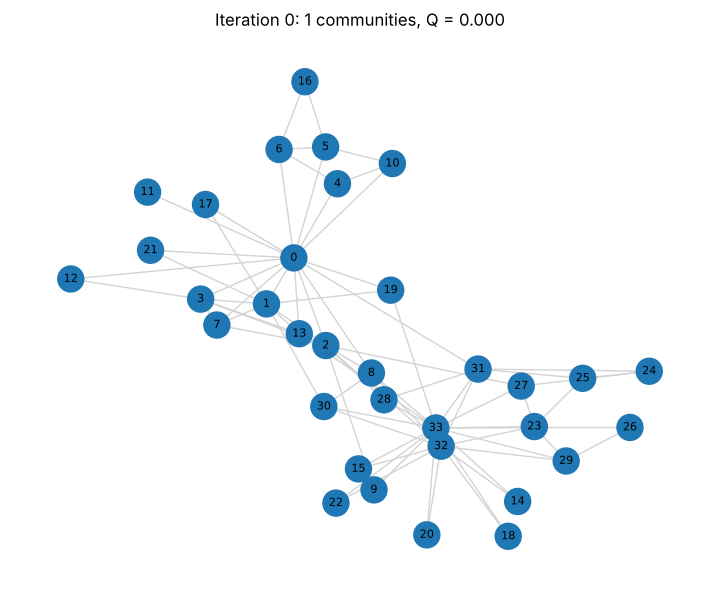

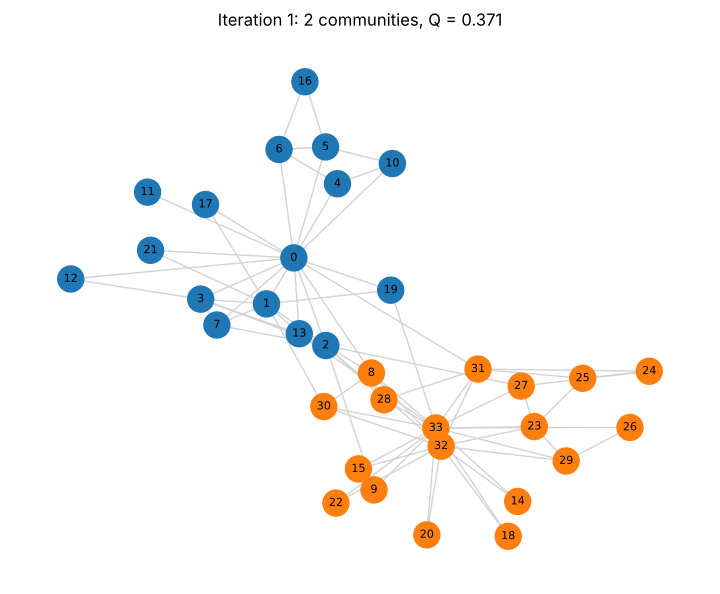

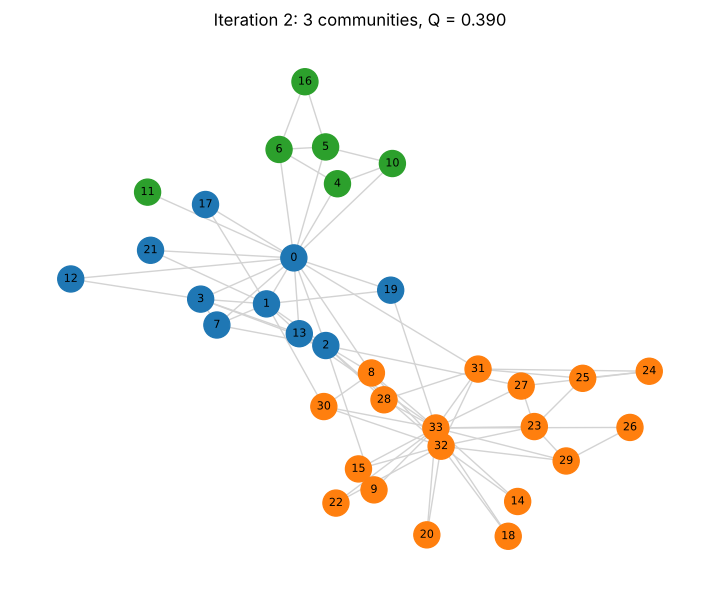

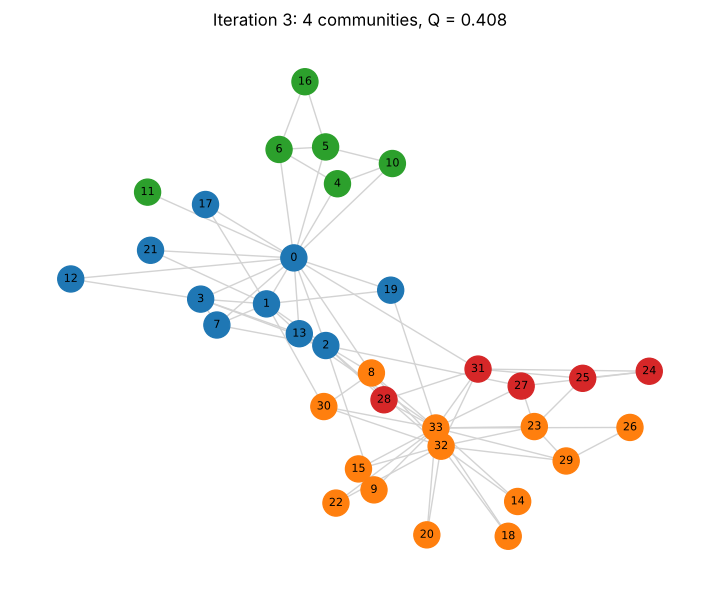

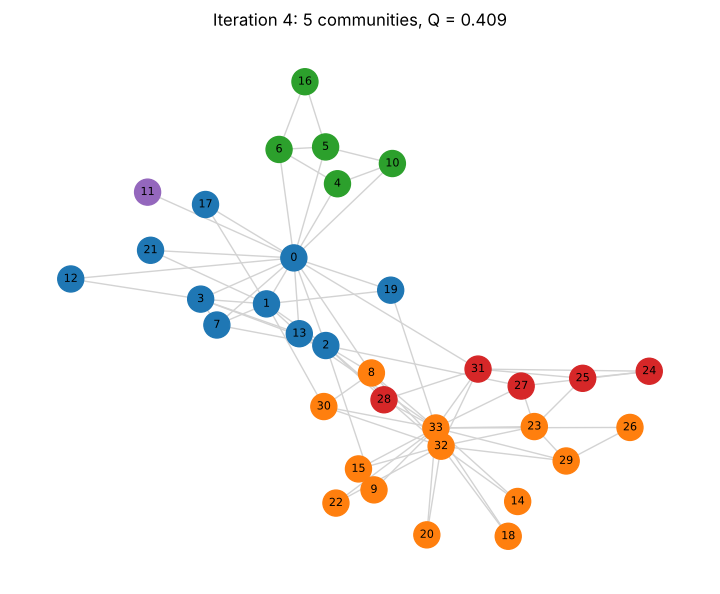

In [6]:
pos = nx.spring_layout(G, seed=42)          # computed once, so the layout is the same every time
colors = plt.cm.tab10.colors

for t, partition in enumerate(history):
    community_of = {v: i for i, c in enumerate(partition) for v in c}
    plt.figure(figsize=(7, 5.5))
    nx.draw(G, pos, with_labels=True, font_size=8, node_size=350, edge_color="lightgray",
            node_color=[colors[community_of[v]] for v in G])
    plt.title(f"Iteration {t}: {len(partition)} communities, Q = {modularity(partition):.3f}")
    plt.savefig(f"assets/partition_iter{t}.png", bbox_inches="tight")
    plt.show()

## 6. Compute the node metrics after each split
After each split, compute degree centrality, betweenness centrality, closeness centrality and clustering with NetworkX. Each node is measured inside its own community (the subgraph of its community), and the results are stored in a dictionary keyed by iteration number.
On the whole graph these values never change, so measuring inside the communities shows how the splits change each node's role. Iteration 0 is the normal whole-graph value.

In [7]:
functions = {
    "Degree centrality": nx.degree_centrality,
    "Betweenness centrality": nx.betweenness_centrality,
    "Closeness centrality": nx.closeness_centrality,
    "Clustering coefficient": nx.clustering,
}

metrics = {}                                   # metrics[iteration][metric name][node]
for t, partition in enumerate(history):
    metrics[t] = {name: {} for name in functions}
    for community in partition:
        H = G.subgraph(community)
        for name, f in functions.items():
            if len(community) == 1:            # a single node has no neighbours: value 0
                metrics[t][name][community[0]] = 0.0
            else:
                metrics[t][name].update(f(H))

# one table per metric: rows = nodes, columns = iterations
tables = {name: pd.DataFrame({t: metrics[t][name] for t in metrics}).sort_index() for name in functions}
tables["Degree centrality"].head()

,0,1,2,3,4
0,0.484848,0.933333,1.000000,1.000000,1.000000
1,0.272727,0.533333,0.888889,0.888889,0.888889
2,0.303030,0.333333,0.555556,0.555556,0.555556
3,0.181818,0.400000,0.666667,0.666667,0.666667
4,0.090909,0.200000,0.400000,0.400000,0.500000


## 7. Plot each metric against the iteration number
One line per node. The 5 nodes with the highest average degree centrality are coloured (the same nodes in all four plots) and the others are grey, to see how each node's metric changes as the communities form.

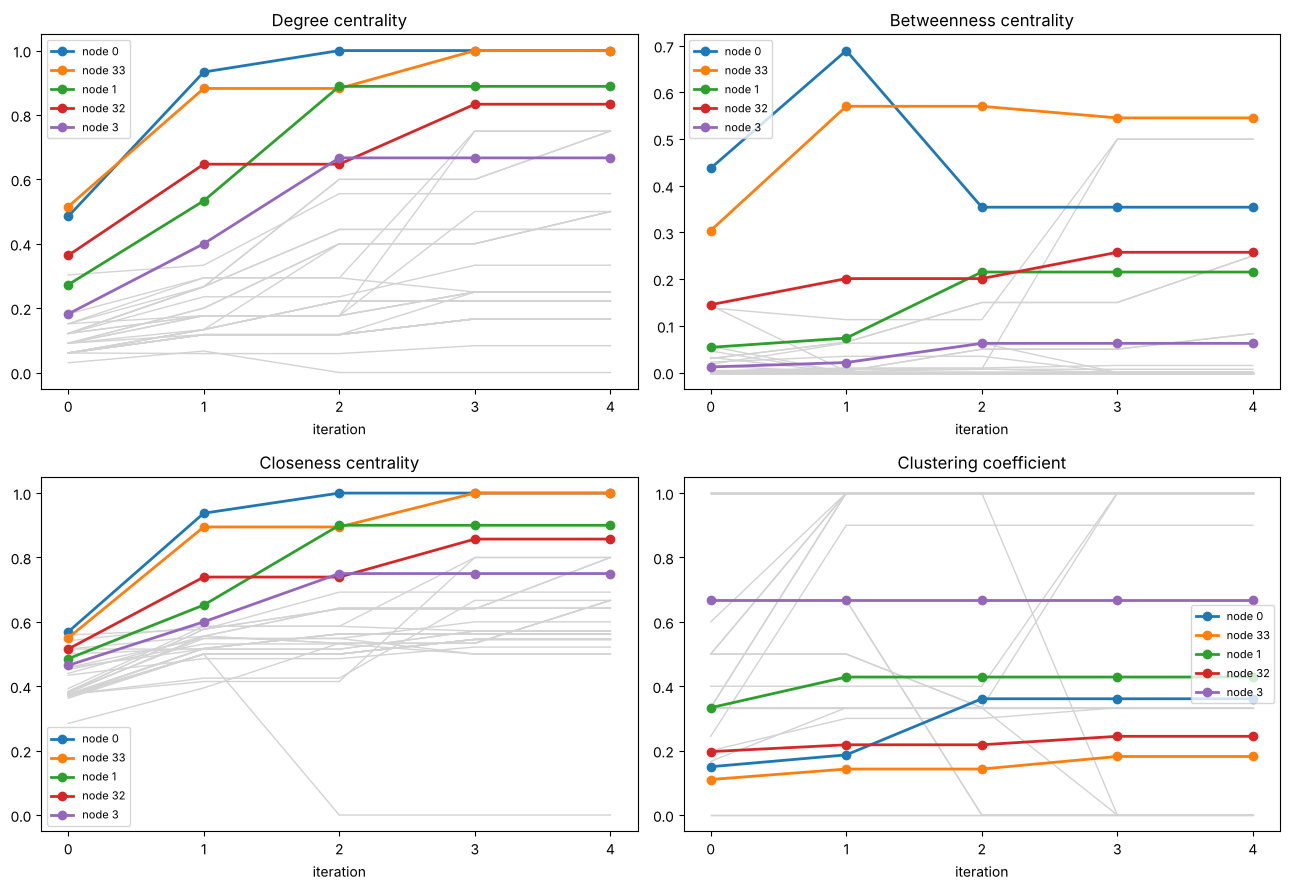

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
top5 = tables["Degree centrality"].mean(axis=1).sort_values(ascending=False).index[:5]

for ax, (name, table) in zip(axes.flat, tables.items()):
    for v in table.index:
        if v not in top5:
            ax.plot(table.columns, table.loc[v], color="lightgray", lw=1)
    for i, v in enumerate(top5):
        ax.plot(table.columns, table.loc[v], marker="o", lw=2, color=colors[i], label=f"node {v}")
    ax.set_title(name)
    ax.set_xlabel("iteration")
    ax.set_xticks(list(table.columns))
    ax.legend(fontsize=8)

plt.tight_layout()
plt.savefig("assets/metrics_vs_iteration.png", bbox_inches="tight")
plt.show()

## 8. Discussion

### 8.1 Central nodes across iterations
Nodes 0 and 33, the instructor and the officer, remain the most central nodes throughout. Both are in the top 3 for degree and closeness at every iteration, and by iteration 4 they have degree and closeness equal to 1.0, meaning each is directly connected to every member of its community. Nodes 32 and 1 come next: node 32 stays high alongside node 33, and node 1 rises in degree from 0.27 to 0.89 alongside node 0. Clustering has different leaders (nodes 7, 8, 26 and 30), while the hubs have low clustering because they connect people who do not know each other.

### 8.2 Changes in betweenness and closeness
Betweenness changes more than any other metric. Node 0 rises from 0.438 to 0.690 at iteration 1 and then falls to 0.354 at iteration 2, when nodes 4, 5, 6, 10 and 16 leave its community; they were only reachable through node 0, so many shortest paths no longer pass through it. Node 33 stays high (0.304 at the start, 0.545 at the end) because it remains the centre of the large community. Nodes 31 and 24 are low until iteration 3 and then jump to 0.50, because they become the connectors of the new 5-node community. Closeness, on the other hand, rises for most nodes after each split because distances within a community are shorter; for node 0 it goes from 0.569 to 0.938 and then to 1.0.

### 8.3 Effect of smaller communities on the metrics
Degree and closeness rise mostly because they are divided by the community size: node 24 has 3 neighbours throughout, but its degree centrality goes from 0.09 to 0.75. Betweenness depends on shortest paths, but it becomes coarse in small communities, where a single node can lie on most of the paths. Clustering rises when edges to other communities are removed (node 0 goes from 0.15 to 0.36), and a community with a single node (node 11) has no neighbours, so all its metrics are 0. The rankings also change: the correlation with the iteration-0 ranking falls to 0.81 for degree, 0.61 for betweenness, 0.53 for closeness and 0.67 for clustering.

### 8.4 Final community structure
The algorithm ends with 5 communities and Q = 0.409, of sizes 10, 13, 5, 5 and 1. The 10-node community contains node 0 (nodes 0, 1, 2, 3, 7, 12, 13, 17, 19, 21) and the 13-node community contains node 33 (nodes 8, 9, 14, 15, 18, 20, 22, 23, 26, 29, 30, 32, 33); the other communities are two groups of 5 nodes (4, 5, 6, 10, 16 and 24, 25, 27, 28, 31) and the single node 11. The first split (16 and 18 nodes) matches the real club split for 33 of 34 members, with only node 8 misclassified. Modularity goes 0 → 0.372 → 0.390 → 0.408 → 0.409, so most of the gain comes from the first three splits; the last split adds only 0.0013 and isolates node 11, which has a single connection.

### 8.5 Conclusion
Spectral modularity partitioning recovers the real split of the club almost exactly from the graph structure alone, and further splitting reveals sub-groups inside each faction. Nodes 0 and 33 remain the central nodes of their communities throughout, while the brokers (betweenness) change as the communities get smaller. Metric values inside small communities are inflated by the smaller size, so rankings are more meaningful than raw values. The last split, which isolates node 11, adds almost nothing, so 4 communities is arguably the more meaningful result.

## References
- M. E. J. Newman (2006). Modularity and community structure in networks. *PNAS* 103(23):8577–8582.
- W. W. Zachary (1977). An information flow model for conflict and fission in small groups. *Journal of Anthropological Research* 33(4):452–473.